<center><h1>Keehan_Alyssa_HW8</h1></center>

Name: Alyssa Keehan
<br>
Github Username: akeehan56
<br>
GitHub Links: [Class Repo](https://github.com/akeehan56/DSCI552) | [HW8](https://github.com/akeehan56/DSCI552/tree/main/HW8)
<br>
Email: akeehan@usc.edu
<br>
USC ID: 3429542433

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from copy import deepcopy
from sklearn.base import clone
from sklearn.model_selection import (train_test_split,StratifiedKFold,GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,roc_curve,confusion_matrix,ConfusionMatrixDisplay)

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [26]:
data_dir = Path("../data")
measurements = ["radius", "texture", "perimeter", "area", "smoothness","compactness", "concavity", "concave_points", "symmetry","fractal_dimension"]
statistics = ["mean", "se", "worst"]
wdbc_columns = (
    ["id", "diagnosis"]
    + [f"{measurement}_{stat}" for stat in statistics for measurement in measurements]
)
wdbc = pd.read_csv(data_dir / "wdbc.data",header=None,names=wdbc_columns)
wdbc["diagnosis"] = wdbc["diagnosis"].map({"B": 0, "M": 1})
X_wdbc = wdbc.drop(columns=["id", "diagnosis"])
y_wdbc = wdbc["diagnosis"]
print("WDBC:", wdbc.shape)
display(wdbc.head())

WDBC: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

##### Train an L1-penalized SVM to classify the data. Use 5 fold cross validation to choose the penalty parameter. Use normalized data.

In [27]:
C_values = np.logspace(-3, 3, 7)
simulation_results = []
first_run_results = None
for run in range(30):
    seed = 42 + run

    X_train, X_test, y_train, y_test = train_test_split(X_wdbc,y_wdbc,test_size=0.20,stratify=y_wdbc,random_state=seed)

    model_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(penalty="l1",dual=False,max_iter=100000,tol=1e-3,random_state=seed))])
    cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=seed)
    search = GridSearchCV(estimator=model_pipeline,param_grid={"svm__C": C_values},scoring="accuracy",cv=cv,n_jobs=-1)

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    train_predictions = best_model.predict(X_train)
    test_predictions = best_model.predict(X_test)

    train_scores = best_model.decision_function(X_train)
    test_scores = best_model.decision_function(X_test)

    simulation_results.append({
        "run": run + 1,
        "best_C": search.best_params_["svm__C"],
        "train_accuracy": accuracy_score(y_train, train_predictions),
        "train_precision": precision_score(y_train, train_predictions, zero_division=0),
        "train_recall": recall_score(y_train, train_predictions, zero_division=0),
        "train_f1": f1_score(y_train, train_predictions, zero_division=0),
        "train_auc": roc_auc_score(y_train, train_scores),
        "test_accuracy": accuracy_score(y_test, test_predictions),
        "test_precision": precision_score(y_test, test_predictions, zero_division=0),
        "test_recall": recall_score(y_test, test_predictions, zero_division=0),
        "test_f1": f1_score(y_test, test_predictions, zero_division=0),
        "test_auc": roc_auc_score(y_test, test_scores)
    })

    if run == 0:
        first_run_results = {
            "y_train": y_train,
            "train_predictions": train_predictions,
            "train_scores": train_scores,
            "y_test": y_test,
            "test_predictions": test_predictions,
            "test_scores": test_scores
        }

##### Report the average accuracy, precision, recall, F1-score, and AUC, for both training and test sets over your M runs

In [28]:
results_df = pd.DataFrame(simulation_results)
metrics = ["accuracy", "precision", "recall", "f1", "auc"]
average_scores = pd.DataFrame({
    "Training average": [results_df[f"train_{metric}"].mean() for metric in metrics],
    "Test average": [results_df[f"test_{metric}"].mean() for metric in metrics]
}, index=[metric.upper() for metric in metrics])

average_scores

,Training average,Test average
ACCURACY,0.987399,0.973684
PRECISION,0.993796,0.975691
RECALL,0.972353,0.953175
F1,0.982934,0.963878
AUC,0.997602,0.993221


##### Plot the ROC and report the confusion matrix for training and testing in one of the runs.

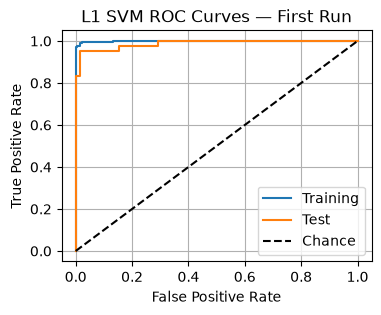

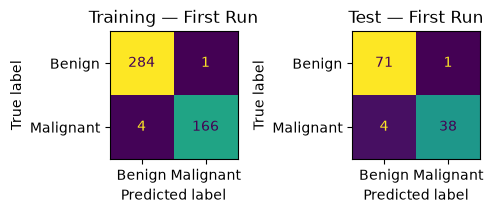

In [29]:
train_fpr, train_tpr, _ = roc_curve(first_run_results["y_train"],first_run_results["train_scores"])
test_fpr, test_tpr, _ = roc_curve(first_run_results["y_test"],first_run_results["test_scores"])

plt.figure(figsize=(4, 3))
plt.plot(train_fpr, train_tpr, label="Training")
plt.plot(test_fpr, test_tpr, label="Test")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("L1 SVM ROC Curves — First Run")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(first_run_results["y_train"],first_run_results["train_predictions"],
                                        labels=[0, 1],display_labels=["Benign", "Malignant"],ax=axes[0],colorbar=False)
axes[0].set_title("Training — First Run")

ConfusionMatrixDisplay.from_predictions(first_run_results["y_test"],first_run_results["test_predictions"],labels=[0, 1],
                                        display_labels=["Benign", "Malignant"],ax=axes[1],colorbar=False)
axes[1].set_title("Test — First Run")

plt.tight_layout()
plt.show()

**Answer:**

Across 30 runs, the model achieved average test accuracy of 0.9737, precision of 0.9757, recall of 0.9532, F1-score of 0.9639, and AUC of 0.9932. The training and test ROC curves were both close to the upper-left corner, indicating strong classification performance. In the first run’s test confusion matrix, the model correctly classified 71 benign and 38 malignant cases, misclassified 1 benign case as malignant, and misclassified 4 malignant cases as benign.

#### (ii) Semi-Supervised Learning/ Self-training

##### (A) Train an L1-penalized SVM on semi-supervised data

In [30]:
self_training_states = []

for run in range(30):
    seed = 42 + run

    X_train, X_test, y_train, y_test = train_test_split(X_wdbc,y_wdbc,test_size=0.20,stratify=y_wdbc,random_state=seed)
    labeled_positions, unlabeled_positions = train_test_split(np.arange(len(y_train)),train_size=0.50,stratify=y_train,random_state=seed)
    labeled_X = X_train.iloc[labeled_positions].copy()
    labeled_y = y_train.iloc[labeled_positions].copy()

    initial_pipeline = Pipeline([("scaler", StandardScaler()),("svm", LinearSVC(penalty="l1",dual=False,max_iter=100000,tol=1e-3,random_state=seed))])
    cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=seed)
    search = GridSearchCV(estimator=initial_pipeline,param_grid={"svm__C": C_values},scoring="accuracy",cv=cv,n_jobs=-1)

    search.fit(labeled_X, labeled_y)

    self_training_states.append({"run": run + 1,"X_train": X_train,"X_test": X_test,"y_train": y_train,"y_test": y_test,"labeled_X": labeled_X,"labeled_y": labeled_y,
        "unlabeled_positions": list(unlabeled_positions),"initial_model": search.best_estimator_,"best_C": search.best_params_["svm__C"]})

##### (B) Add pseudo-labeled observations and evaluate

In [31]:
self_training_results = []
first_self_training_run = None

for state in self_training_states:
    X_train = state["X_train"]
    X_test = state["X_test"]
    y_train = state["y_train"]
    y_test = state["y_test"]

    labeled_X = state["labeled_X"].copy()
    labeled_y = state["labeled_y"].copy()
    unlabeled_positions = state["unlabeled_positions"].copy()
    best_model = deepcopy(state["initial_model"])

    while unlabeled_positions:
        unlabeled_X = X_train.iloc[unlabeled_positions]
        decision_scores = best_model.decision_function(unlabeled_X)
        farthest_index = np.argmax(np.abs(decision_scores))
        selected_position = unlabeled_positions.pop(farthest_index)
        pseudo_label = int(decision_scores[farthest_index] > 0)
        labeled_X = pd.concat([labeled_X,X_train.iloc[[selected_position]]])
        labeled_y = pd.concat([labeled_y,pd.Series([pseudo_label],index=[X_train.index[selected_position]])])
        best_model.fit(labeled_X, labeled_y)

    train_predictions = best_model.predict(X_train)
    test_predictions = best_model.predict(X_test)

    train_scores = best_model.decision_function(X_train)
    test_scores = best_model.decision_function(X_test)

    self_training_results.append({
        "run": state["run"],"best_C": state["best_C"],
        "train_accuracy": accuracy_score(y_train, train_predictions),"train_precision": precision_score(y_train, train_predictions, zero_division=0),
        "train_recall": recall_score(y_train, train_predictions, zero_division=0),"train_f1": f1_score(y_train, train_predictions, zero_division=0),
        "train_auc": roc_auc_score(y_train, train_scores),"test_accuracy": accuracy_score(y_test, test_predictions),
        "test_precision": precision_score(y_test, test_predictions, zero_division=0),"test_recall": recall_score(y_test, test_predictions, zero_division=0),
        "test_f1": f1_score(y_test, test_predictions, zero_division=0),"test_auc": roc_auc_score(y_test, test_scores)})

    if state["run"] == 1:
        first_self_training_run = {"y_train": y_train, "train_predictions": train_predictions, "train_scores": train_scores,
                                   "y_test": y_test,"test_predictions": test_predictions,"test_scores": test_scores}

##### Report avg. metrics

In [32]:
self_training_df = pd.DataFrame(self_training_results)

metrics = ["accuracy", "precision", "recall", "f1", "auc"]

self_training_average_scores = pd.DataFrame({
    "Training average": [
        self_training_df[f"train_{metric}"].mean()
        for metric in metrics
    ],
    "Test average": [
        self_training_df[f"test_{metric}"].mean()
        for metric in metrics
    ]
}, index=[metric.upper() for metric in metrics])

self_training_average_scores

,Training average,Test average
ACCURACY,0.973260,0.964327
PRECISION,0.980813,0.964490
RECALL,0.947647,0.939683
F1,0.963607,0.950860
AUC,0.994026,0.992008


##### ROC curves and confusion matrices for the first run

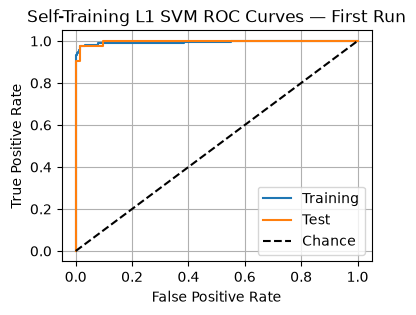

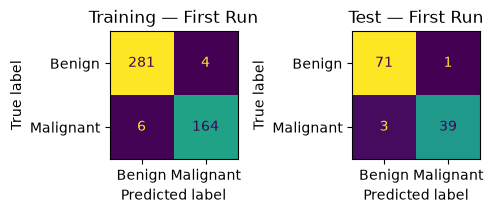

In [33]:
train_fpr, train_tpr, _ = roc_curve(first_self_training_run["y_train"], first_self_training_run["train_scores"])

test_fpr, test_tpr, _ = roc_curve(first_self_training_run["y_test"], first_self_training_run["test_scores"])

plt.figure(figsize=(4, 3))
plt.plot(train_fpr, train_tpr, label="Training")
plt.plot(test_fpr, test_tpr, label="Test")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Self-Training L1 SVM ROC Curves — First Run")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(first_self_training_run["y_train"],first_self_training_run["train_predictions"],
                                        labels=[0, 1],display_labels=["Benign", "Malignant"],ax=axes[0],colorbar=False)
axes[0].set_title("Training — First Run")

ConfusionMatrixDisplay.from_predictions(first_self_training_run["y_test"],first_self_training_run["test_predictions"],
                                        labels=[0, 1],display_labels=["Benign", "Malignant"],ax=axes[1],colorbar=False)
axes[1].set_title("Test — First Run")

plt.tight_layout()
plt.show()

**Answer:**

Across 30 runs, the average test accuracy was 0.9643, precision was 0.9645, recall was 0.9397, F1-score was 0.9509, and AUC was 0.9920. The first-run ROC curves were close to the upper-left corner, indicating strong discrimination. In that run’s test confusion matrix, the model correctly classified 71 benign and 39 malignant cases; it misclassified 1 benign case as malignant and 3 malignant cases as benign.

Both models performed strongly, and their ROC curves were close to the upper-left corner; the AUC difference was small. The supervised model’s advantage is consistent with training on the true labels for all training observations, while self-training began with only half labeled and assigned predicted labels to the rest. In the first-run test confusion matrices, self-training missed 3 malignant cases compared with 4 for the supervised model, though the 30-run averages favor the supervised model.

#### (iii) Unsupervised Learning

##### (A) Split the data and run K-means with random initializations

In [34]:
kmeans_states = []

for run in range(30):
    seed = 42 + run
    X_train, X_test, y_train, y_test = train_test_split(X_wdbc,y_wdbc,test_size=0.20,stratify=y_wdbc,random_state=seed)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    kmeans = KMeans(n_clusters=2,init="random",n_init=20,random_state=seed)
    kmeans.fit(X_train_scaled)
    kmeans_states.append({"run": run + 1,"X_train_scaled": X_train_scaled,"X_test_scaled": X_test_scaled,"y_train": y_train,"y_test": y_test,"kmeans": kmeans})

**Answer:**

K-means can converge to a local minimum, so I used 20 random initializations by setting n_init=20. The algorithm runs K-means from different starting centroids and keeps the solution with the lowest inertia. This makes it less likely that the reported clustering is based on a poor initialization, although it does not guarantee the global optimum.

##### (B) Label each cluster using its 30 closest training observations

In [11]:
kmeans_results = []
first_kmeans_run = None

for state in kmeans_states:
    kmeans = state["kmeans"]
    X_train_scaled = state["X_train_scaled"]
    y_train = state["y_train"]
    distances_to_centers = kmeans.transform(X_train_scaled)
    cluster_to_class = {}

    for cluster in range(2):
        closest_positions = np.argsort(
            distances_to_centers[:, cluster]
        )[:30]

        closest_labels = y_train.iloc[closest_positions]

        cluster_to_class[cluster] = int(
            closest_labels.mode().iloc[0]
        )

    state["cluster_to_class"] = cluster_to_class

    train_clusters = kmeans.labels_
    train_predictions = np.array([
        cluster_to_class[cluster]
        for cluster in train_clusters
    ])

    negative_train_distances = -distances_to_centers
    train_affinities = np.exp(negative_train_distances - negative_train_distances.max(axis=1, keepdims=True))
    train_affinities /= train_affinities.sum(axis=1, keepdims=True)

    malignant_clusters = [
        cluster
        for cluster, predicted_class in cluster_to_class.items()
        if predicted_class == 1
    ]

    train_scores = train_affinities[:, malignant_clusters].sum(axis=1)

    kmeans_results.append({
        "run": state["run"],"train_accuracy": accuracy_score(y_train, train_predictions),"train_precision": precision_score(y_train, train_predictions, zero_division=0),
        "train_recall": recall_score(y_train, train_predictions, zero_division=0),"train_f1": f1_score(y_train, train_predictions, zero_division=0),
        "train_auc": roc_auc_score(y_train, train_scores)})

    if state["run"] == 1:
        first_kmeans_run = {"y_train": y_train,"train_predictions": train_predictions,"train_scores": train_scores}

##### (C) Classify the test data and calculate the averages

In [12]:
for index, state in enumerate(kmeans_states):
    kmeans = state["kmeans"]
    X_test_scaled = state["X_test_scaled"]
    y_test = state["y_test"]
    cluster_to_class = state["cluster_to_class"]

    test_clusters = kmeans.predict(X_test_scaled)
    test_predictions = np.array([
        cluster_to_class[cluster]
        for cluster in test_clusters
    ])

    test_distances = kmeans.transform(X_test_scaled)
    negative_test_distances = -test_distances
    test_affinities = np.exp(negative_test_distances - negative_test_distances.max(axis=1, keepdims=True))
    test_affinities /= test_affinities.sum(axis=1, keepdims=True)

    malignant_clusters = [
        cluster
        for cluster, predicted_class in cluster_to_class.items()
        if predicted_class == 1
    ]

    test_scores = test_affinities[:, malignant_clusters].sum(axis=1)

    kmeans_results[index].update({
        "test_accuracy": accuracy_score(y_test, test_predictions),"test_precision": precision_score(y_test, test_predictions, zero_division=0),
        "test_recall": recall_score(y_test, test_predictions, zero_division=0),
        "test_f1": f1_score(y_test, test_predictions, zero_division=0),"test_auc": roc_auc_score(y_test, test_scores)})
    if state["run"] == 1:
        first_kmeans_run.update({"y_test": y_test,"test_predictions": test_predictions,"test_scores": test_scores})

kmeans_results_df = pd.DataFrame(kmeans_results)
metrics = ["accuracy", "precision", "recall", "f1", "auc"]
kmeans_average_scores = pd.DataFrame({
    "Training average": [kmeans_results_df[f"train_{metric}"].mean()
        for metric in metrics
    ],
    "Test average": [kmeans_results_df[f"test_{metric}"].mean()
        for metric in metrics
    ]
}, index=[metric.upper() for metric in metrics])

kmeans_average_scores

,Training average,Test average
ACCURACY,0.909744,0.913450
PRECISION,0.924331,0.919923
RECALL,0.826667,0.838889
F1,0.872488,0.876421
AUC,0.974626,0.975220


##### ROC curves and confusion matrices for the first run

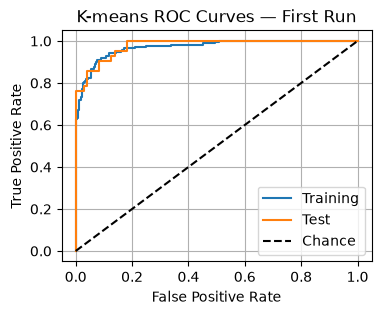

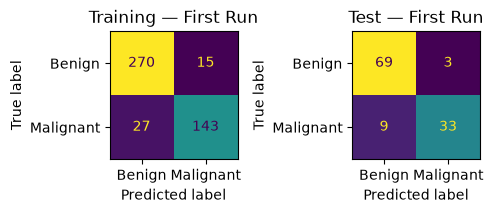

In [13]:
train_fpr, train_tpr, _ = roc_curve(first_kmeans_run["y_train"],first_kmeans_run["train_scores"])
test_fpr, test_tpr, _ = roc_curve(first_kmeans_run["y_test"],first_kmeans_run["test_scores"])

plt.figure(figsize=(4, 3))
plt.plot(train_fpr, train_tpr, label="Training")
plt.plot(test_fpr, test_tpr, label="Test")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("K-means ROC Curves — First Run")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(first_kmeans_run["y_train"],first_kmeans_run["train_predictions"],
                                        labels=[0, 1],display_labels=["Benign", "Malignant"],ax=axes[0],colorbar=False)
axes[0].set_title("Training — First Run")
ConfusionMatrixDisplay.from_predictions(first_kmeans_run["y_test"],first_kmeans_run["test_predictions"],
                                        labels=[0, 1],display_labels=["Benign", "Malignant"],ax=axes[1],colorbar=False)
axes[1].set_title("Test — First Run")
plt.tight_layout()
plt.show()

**Answer:**

Across 30 runs, the average test accuracy was 0.9135, precision 0.9199, recall 0.8389, F1-score 0.8764, and AUC 0.9752. In the first-run test confusion matrix, it correctly classified 69 benign and 33 malignant cases, while misclassifying 3 benign cases as malignant and 9 malignant cases as benign.

K-means had lower average test scores than both SVM approaches. The supervised SVM performed best overall so far, and self-training was slightly behind it; K-means had the largest drop, especially in recall and F1-score. Its ROC curve still performed well above chance, but the results suggest that these SVM methods classified the two cancer types more effectively.

#### (iv) Spectral Clustering

**What is spectral clustering?**

Spectral clustering represents observations as a similarity graph, where observations with similar features are connected. It uses eigenvectors of the graph Laplacian to create a lower-dimensional representation of the graph, then clusters observations in that representation. This can identify non-convex clusters that may not be well represented by distances to cluster centers.

#### Create clusters for 30 train/test splits

In [14]:
X_train_diag, X_test_diag, y_train_diag, y_test_diag = train_test_split(X_wdbc,y_wdbc,test_size=0.20,stratify=y_wdbc,random_state=42)
scaler_diag = StandardScaler()
X_train_diag_scaled = scaler_diag.fit_transform(X_train_diag)
target_balance = np.sort(y_train_diag.value_counts(normalize=True).to_numpy())
gamma_candidates = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
gamma_balance_results = []
for gamma_value in gamma_candidates:
    spectral_diag = SpectralClustering(n_clusters=2,affinity="rbf",gamma=gamma_value,assign_labels="kmeans",n_init=10,random_state=42)
    cluster_labels_diag = spectral_diag.fit_predict(X_train_diag_scaled)
    cluster_balance = np.sort(np.bincount(cluster_labels_diag, minlength=2) / len(cluster_labels_diag))
    gamma_balance_results.append({"gamma": gamma_value,"smaller_cluster_fraction": cluster_balance[0],
                                  "larger_cluster_fraction": cluster_balance[1],"balance_error": np.abs(cluster_balance - target_balance).sum()})
gamma_balance_df = pd.DataFrame(gamma_balance_results)
display(gamma_balance_df.sort_values("balance_error").round(4))

,gamma,smaller_cluster_fraction,larger_cluster_fraction,balance_error
0,0.001,0.3407,0.6593,0.0659
1,0.003,0.3055,0.6945,0.1363
2,0.010,0.2747,0.7253,0.1978
3,0.030,0.0044,0.9956,0.7385
4,0.100,0.0044,0.9956,0.7385
5,0.300,0.0044,0.9956,0.7385
6,1.000,0.0044,0.9956,0.7385


**Answer:**

I selected gamma = 0.001 because it had the lowest balance error among the candidate values tested. It produced clusters containing approximately 34.1% and 65.9% of the observations. The training classes contain approximately 37.4% and 62.6%, so the selected clusters are close to the class balance but do not match it exactly. A finer search around gamma = 0.001 could be used to look for a closer match.

In [15]:
selected_gamma = 0.001
spectral_states = []

for run in range(30):
    seed = 42 + run
    X_train, X_test, y_train, y_test = train_test_split(X_wdbc,y_wdbc,test_size=0.20,stratify=y_wdbc,random_state=seed)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    X_combined_scaled = np.vstack([X_train_scaled,X_test_scaled])
    spectral_model = SpectralClustering(n_clusters=2,affinity="rbf",gamma=selected_gamma,assign_labels="kmeans",n_init=10,random_state=seed)
    combined_cluster_labels = spectral_model.fit_predict(X_combined_scaled)
    n_train = len(y_train)
    spectral_states.append({"run": run + 1,"y_train": y_train,"y_test": y_test,
                            "train_cluster_labels": combined_cluster_labels[:n_train],"test_cluster_labels": combined_cluster_labels[n_train:]})

##### Assign each cluster a class using the training labels

In [16]:
spectral_results = []
first_spectral_run = None

for state in spectral_states:
    y_train = state["y_train"].to_numpy()
    train_cluster_labels = state["train_cluster_labels"]
    cluster_to_class = {}
    cluster_malignant_rate = {}

    for cluster in range(2):
        members = train_cluster_labels == cluster
        if members.any():
            malignant_rate = y_train[members].mean()
        else:
            malignant_rate = y_train.mean()
        cluster_malignant_rate[cluster] = malignant_rate
        cluster_to_class[cluster] = int(malignant_rate >= 0.5)

    state["cluster_to_class"] = cluster_to_class
    state["cluster_malignant_rate"] = cluster_malignant_rate

    train_predictions = np.array([
        cluster_to_class[cluster]
        for cluster in train_cluster_labels
    ])
    train_scores = np.array([
        cluster_malignant_rate[cluster]
        for cluster in train_cluster_labels
    ])

    spectral_results.append({
        "run": state["run"],"train_accuracy": accuracy_score(y_train, train_predictions),
        "train_precision": precision_score(y_train, train_predictions, zero_division=0),"train_recall": recall_score(y_train, train_predictions, zero_division=0),
        "train_f1": f1_score(y_train, train_predictions, zero_division=0),"train_auc": roc_auc_score(y_train, train_scores)})

    if state["run"] == 1:
        first_spectral_run = {"y_train": y_train,"train_predictions": train_predictions,"train_scores": train_scores}

##### Score test data and summarize the 30 runs

In [17]:
for index, state in enumerate(spectral_states):
    y_test = state["y_test"].to_numpy()
    test_cluster_labels = state["test_cluster_labels"]
    cluster_to_class = state["cluster_to_class"]
    cluster_malignant_rate = state["cluster_malignant_rate"]

    test_predictions = np.array([
        cluster_to_class[cluster]
        for cluster in test_cluster_labels
    ])

    test_scores = np.array([
        cluster_malignant_rate[cluster]
        for cluster in test_cluster_labels
    ])

    spectral_results[index].update({"test_accuracy": accuracy_score(y_test, test_predictions),"test_precision": precision_score(y_test, test_predictions, zero_division=0),
                                    "test_recall": recall_score(y_test, test_predictions, zero_division=0),"test_f1": f1_score(y_test, test_predictions, zero_division=0),
                                    "test_auc": roc_auc_score(y_test, test_scores)})
    if state["run"] == 1:
        first_spectral_run.update({"y_test": y_test,"test_predictions": test_predictions,"test_scores": test_scores})

spectral_results_df = pd.DataFrame(spectral_results)
metrics = ["accuracy", "precision", "recall", "f1", "auc"]

spectral_average_scores = pd.DataFrame({
    "Training average": [spectral_results_df[f"train_{metric}"].mean()
        for metric in metrics],
    "Test average": [spectral_results_df[f"test_{metric}"].mean()
        for metric in metrics]}, index=[metric.upper() for metric in metrics])

spectral_average_scores

,Training average,Test average
ACCURACY,0.907839,0.913158
PRECISION,0.927466,0.922321
RECALL,0.817647,0.835714
F1,0.868879,0.875733
AUC,0.889642,0.897024


##### ROC curves and confusion matrices for the first run

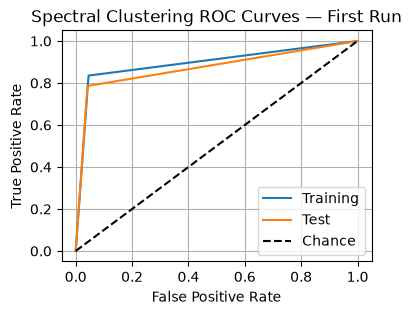

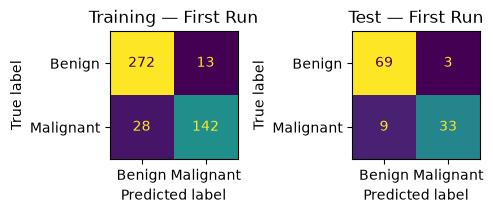

In [18]:
train_fpr, train_tpr, _ = roc_curve(first_spectral_run["y_train"],first_spectral_run["train_scores"])
test_fpr, test_tpr, _ = roc_curve(first_spectral_run["y_test"],first_spectral_run["test_scores"])

plt.figure(figsize=(4, 3))
plt.plot(train_fpr, train_tpr, label="Training")
plt.plot(test_fpr, test_tpr, label="Test")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Spectral Clustering ROC Curves — First Run")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(first_spectral_run["y_train"],first_spectral_run["train_predictions"],labels=[0, 1],
                                        display_labels=["Benign", "Malignant"],ax=axes[0],colorbar=False)
axes[0].set_title("Training — First Run")
ConfusionMatrixDisplay.from_predictions(first_spectral_run["y_test"],first_spectral_run["test_predictions"],
                                        labels=[0, 1],display_labels=["Benign", "Malignant"],ax=axes[1],colorbar=False)
axes[1].set_title("Test — First Run")

plt.tight_layout()
plt.show()

#### (iv) Compare

In [19]:
model_results = {"Supervised L1 SVM": results_df,"Self-training L1 SVM": self_training_df,"K-means": kmeans_results_df,"Spectral clustering": spectral_results_df}
test_comparison_rows = []
for method, results in model_results.items():
    test_comparison_rows.append({"Method": method,"Accuracy": results["test_accuracy"].mean(),"Precision": results["test_precision"].mean(),
                                 "Recall": results["test_recall"].mean(),"F1-score": results["test_f1"].mean(),"AUC": results["test_auc"].mean()})

test_comparison_table = (pd.DataFrame(test_comparison_rows).set_index("Method"))
display(test_comparison_table.round(4))

,Accuracy,Precision,Recall,F1-score,AUC
Method,,,,,
Supervised L1 SVM,0.9737,0.9757,0.9532,0.9639,0.9932
Self-training L1 SVM,0.9643,0.9645,0.9397,0.9509,0.9920
K-means,0.9135,0.9199,0.8389,0.8764,0.9752
Spectral clustering,0.9132,0.9223,0.8357,0.8757,0.8970


**Answer:**

The supervised L1 SVM had the strongest test performance, with the highest accuracy, recall, F1-score, and AUC; the self-training L1 SVM was a close second. K-means and spectral clustering had similar accuracy (about 0.913), recall (about 0.836–0.839), and F1-score (0.876), though spectral clustering had slightly higher precision. Its AUC was lower than K-means’ (0.8970 versus 0.9752), indicating weaker overall separation of the classes by the scores used for the ROC analysis. Overall, the results show that the supervised approaches performed best, while both clustering methods had lower recall and F1-scores.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [20]:
banknote_columns = ["variance", "skewness", "curtosis", "entropy", "class"]
banknote = pd.read_csv(data_dir / "data_banknote_authentication.txt",header=None,names=banknote_columns,)
X_banknote = banknote.drop(columns="class")
y_banknote = banknote["class"]
print("Banknote:", banknote.shape)
display(banknote.head())

Banknote: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [21]:
X_train, X_test, y_train, y_test = train_test_split(X_banknote,y_banknote,test_size=472,stratify=y_banknote,random_state=552)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (900, 4)
Test set: (472, 4)


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [22]:
X_train_array = np.asarray(X_train)
y_train_array = np.asarray(y_train).ravel()
X_test_array = np.asarray(X_test)
y_test_array = np.asarray(y_test).ravel()

classes = np.unique(y_train_array)
if len(classes) != 2:
    raise ValueError("This code expects a binary classification problem.")

class_indices = {
    label: np.flatnonzero(y_train_array == label)
    for label in classes
}
if min(len(indices) for indices in class_indices.values()) < 5:
    raise ValueError("The training set needs at least 5 examples from each class.")

In [23]:
n_runs = 50
batch_size = 10
n_steps = len(y_train_array) // batch_size  # 90 steps for 900 training rows
passive_errors = np.zeros((n_runs, n_steps))
C_values = [0.1, 1, 10]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for run in range(n_runs):
    rng = np.random.default_rng(42 + run)
    labeled_indices = np.concatenate([
        rng.choice(class_indices[label], size=5, replace=False)
        for label in classes
    ])
    remaining_indices = np.setdiff1d(np.arange(len(y_train_array)),labeled_indices)
    rng.shuffle(remaining_indices)

    for step in range(n_steps):
        model = make_pipeline(StandardScaler(),LinearSVC(penalty="l1",dual=False,max_iter=100000,tol=1e-3,random_state=42 + run))
        search = GridSearchCV(estimator=model,param_grid={"linearsvc__C": C_values},cv=cv,scoring="accuracy")
        search.fit(X_train_array[labeled_indices],y_train_array[labeled_indices])
        test_predictions = search.best_estimator_.predict(X_test_array)
        passive_errors[run, step] = np.mean(test_predictions != y_test_array)
        if step < n_steps - 1:
            next_indices = remaining_indices[:batch_size]
            labeled_indices = np.concatenate([labeled_indices, next_indices])
            remaining_indices = remaining_indices[batch_size:]

#### (ii) Active

In [24]:
active_errors = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    rng = np.random.default_rng(142 + run)
    labeled_indices = np.concatenate([rng.choice(class_indices[label], size=5, replace=False)
        for label in classes])
    remaining_indices = np.setdiff1d(np.arange(len(y_train_array)),labeled_indices)

    for step in range(n_steps):
        model = make_pipeline(StandardScaler(),LinearSVC(penalty="l1",dual=False,max_iter=100000,tol=1e-3,random_state=142 + run))
        search = GridSearchCV(estimator=model,param_grid={"linearsvc__C": [0.1, 1, 10]},cv=cv,scoring="accuracy")
        search.fit(X_train_array[labeled_indices],y_train_array[labeled_indices])
        best_model = search.best_estimator_
        test_predictions = best_model.predict(X_test_array)
        active_errors[run, step] = np.mean(test_predictions != y_test_array)

        if step < n_steps - 1:
            scaler = best_model.named_steps["standardscaler"]
            svm = best_model.named_steps["linearsvc"]
            X_remaining_scaled = scaler.transform(X_train_array[remaining_indices])
            distances = (np.abs(svm.decision_function(X_remaining_scaled))/ np.linalg.norm(svm.coef_))
            closest_positions = np.argsort(distances)[:batch_size]
            next_indices = remaining_indices[closest_positions]
            labeled_indices = np.concatenate([labeled_indices, next_indices])
            remaining_indices = np.delete(remaining_indices, closest_positions)

### (c) Average the 50 test errors

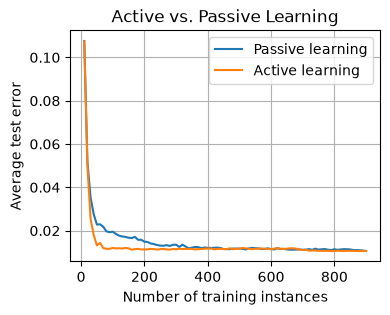

In [25]:
training_sizes = np.arange(10, len(y_train_array) + 1, 10)

mean_passive_error = passive_errors.mean(axis=0)
mean_active_error = np.asarray(active_errors).mean(axis=0)

plt.figure(figsize=(4, 3))
plt.plot(training_sizes, mean_passive_error, label="Passive learning")
plt.plot(training_sizes, mean_active_error, label="Active learning")
plt.xlabel("Number of training instances")
plt.ylabel("Average test error")
plt.title("Active vs. Passive Learning")
plt.legend()
plt.grid(True)
plt.show()

**Answer:**

The average test error decreased for both active and passive learning as the training pool grew. Active learning reduced the error more quickly at first, reaching about 0.01 with fewer training instances, while passive learning improved more gradually and caught up as the pool increased. After roughly 400 training instances, the two methods had very similar test errors, suggesting that active learning’s main advantage was using fewer labeled examples early in training.